<a href="https://colab.research.google.com/github/ErickRicardo1175/riesgo-academico-regresion-clasificacion/blob/main/GRUPO_B_PROYECTO_1ER_PARCIAL_PARTE_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto del 1er Parcial  — Predicción del rendimiento académico con aprendizaje automático

| | |
|---|---|
| **Integrantes** | JORDAN EDUARDO CHANCAY REYES · ERICK RICARDO MUÑIZ RUIZ · DAVID ALEXANDER PAREDES FLORES · SAUL HUMBERTO ZAMBRANO CEDEÑO |
| **Paralelo** | CDDEIA-ELMA-4-1|
| **Grupo** | B |
| **Fecha** | 23 de noviembre de 2026|
| **Asignatura** | APRENDIZAJE AUTOMÁTICO|
| **Docente** | ING. DARWIN ALEXA RODRIGUEZ MERCHÁN MSc|
| | |

## Contexto y objetivo

Una institución educativa quiere identificar a tiempo a los estudiantes en riesgo de reprobar para ofrecerles tutorías. Construimos un pipeline completo sobre el dataset *Student Performance / Student Alcohol Consumption* (Cortez & Silva, 2008). De los dos archivos disponibles (Matemática y Portugués, con las mismas 33 variables) trabajamos únicamente con `student-por.csv` (Portugués). Con él buscamos responder dos preguntas:

1. **Regresión lineal:** ¿qué nota final (`G3`) obtendrá un estudiante?
2. **Regresión logística:** ¿aprobará (`G3 ≥ 10`) o reprobará?

# Parte 1. Análisis exploratorio de datos (EDA)

## 1.1 Carga y estructura del dataset

In [30]:
# ============================================================
# Librerías y configuración general
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sns.set(color_codes=True)
pd.set_option("display.max_columns", 50)

In [31]:
# 1.1 Carga del dataset de Portugués
import kagglehub
from kagglehub import KaggleDatasetAdapter

df_por = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS, "uciml/student-alcohol-consumption", "student-por.csv")

df_por.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


In [32]:
# 1.1 Estructura: filas y columnas
print("Filas:", df_por.shape[0])
print("Columnas:", df_por.shape[1])

Filas: 649
Columnas: 33


In [33]:
# 1.1 Tipos de variables y valores no nulos
df_por.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [34]:
# 1.1 Valores nulos en total
print("Valores Nulos totales:", df_por.isnull().sum().sum())

Valores Nulos totales: 0


In [35]:
# 1.1 Estadísticas descriptivas de las variables numéricas
print("----------------Estadísticas Descriptivas ----------------")
df_por.describe().T.round(2)

----------------Estadísticas Descriptivas ----------------


,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


In [36]:
# 1.1 Estadísticas descriptivas de las variables categóricas
print("------Estadísticas Descriptivas--------")
df_por.select_dtypes(exclude="number").describe().T

------Estadísticas Descriptivas--------


,count,unique,top,freq
school,649,2,GP,423
sex,649,2,F,383
address,649,2,U,452
famsize,649,2,GT3,457
Pstatus,649,2,T,569
Mjob,649,5,other,258
Fjob,649,5,other,367
reason,649,4,course,285
guardian,649,3,mother,455
schoolsup,649,2,no,581


### **Interpretación de 1.1**

**Estructura.** El archivo de Portugués contiene 649 estudiantes y 33 columnas: 16 variables numéricas enteras, como edad, educación de los padres, escalas de 1 a 5, ausencias y notas G1, G2 y G3; y 17 variables categóricas, como escuela, sexo, trabajo de los padres y apoyo escolar. No hay valores nulos. Además, 382 estudiantes también cursan Matemática y aparecen en el otro archivo, por lo que no deben contarse como estudiantes diferentes al combinar ambos datasets.

**Nota final G3.** La media es 11,91, la desviación estándar 3,23 y la mediana 12, con valores entre 0 y 19. La mayoría supera la nota de aprobación de 10 y las calificaciones presentan una dispersión relativamente baja.

**Ausencias.** La mediana es 2, la media 3,66 y el máximo 32. La diferencia entre la media y la mediana indica que algunos estudiantes acumulan muchas ausencias.

**Otras variables.** Las variables ordinales famrel, freetime, goout, Dalc y health utilizan escalas de 1 a 5. En Dalc, que representa el consumo de alcohol entre semana, la mediana es 1, lo que refleja un consumo bajo en la mayoría. Entre las variables categóricas, predominan los estudiantes de la escuela GP, de zonas urbanas y que desean continuar estudios superiores, con 580 de 649 estudiantes. Por tanto, pocos estudiantes no planean seguir estudiando.

## 1.2 Distribuciones

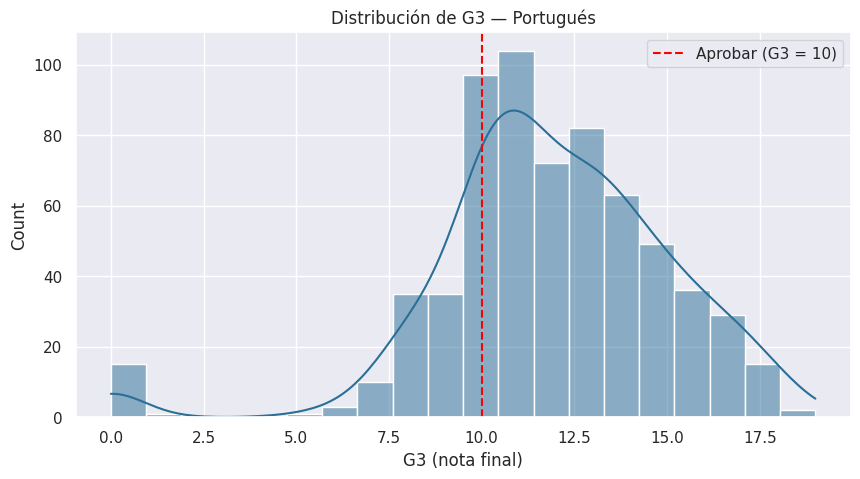

In [37]:
# 1.2 Distribución de G3
plt.figure(figsize=(10, 5))
sns.histplot(df_por["G3"], bins=20, kde=True, color="#2a6f97")
plt.axvline(10, color="red", ls="--", label="Aprobar (G3 = 10)")
plt.title("Distribución de G3 — Portugués")
plt.xlabel("G3 (nota final)")
plt.legend()
plt.show()

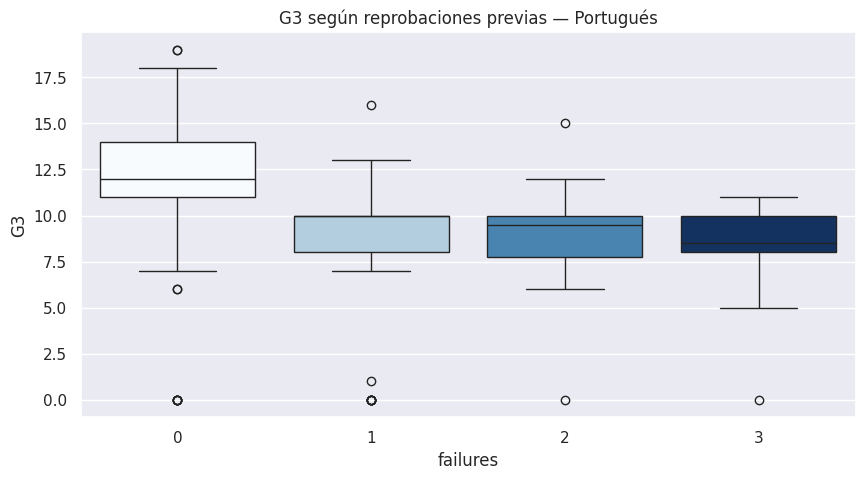

In [38]:
# 1.2 Boxplot: G3 según reprobaciones previas
plt.figure(figsize=(10, 5))
sns.boxplot(x="failures", y="G3", data=df_por, hue="failures", palette="Blues", legend=False)
plt.title("G3 según reprobaciones previas — Portugués")
plt.show()

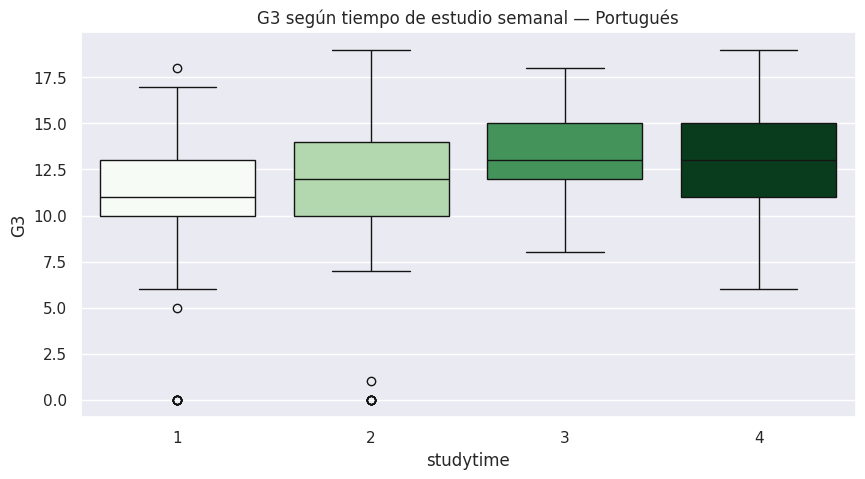

In [39]:
# 1.2 Boxplot: G3 según tiempo de estudio semanal
plt.figure(figsize=(10, 5))
sns.boxplot(x="studytime", y="G3", data=df_por, hue="studytime", palette="Greens", legend=False)
plt.title("G3 según tiempo de estudio semanal — Portugués")
plt.show()

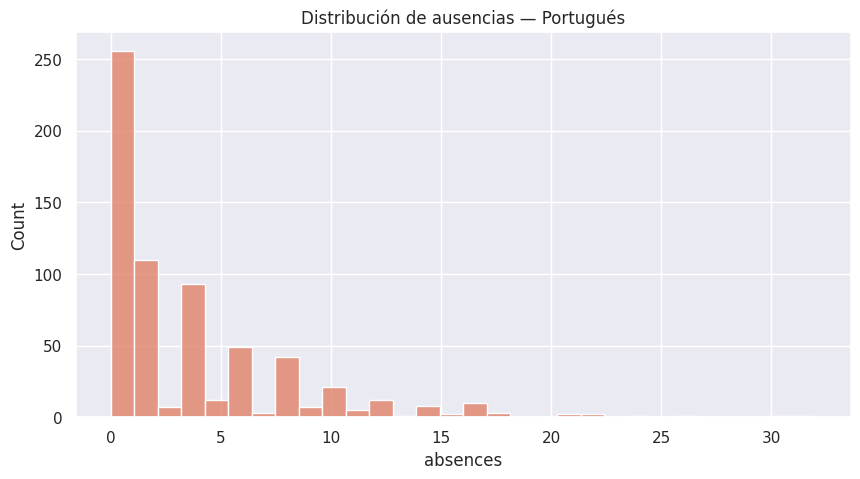

In [40]:
# 1.2 Distribución de ausencias
plt.figure(figsize=(10, 5))
sns.histplot(df_por["absences"], bins=30, color="#e07a5f")
plt.title("Distribución de ausencias — Portugués")
plt.show()

In [41]:
# 1.2 Estudiantes con G3 = 0
n0 = (df_por["G3"] == 0).sum()
print("Estudiantes con G3 = 0:", n0, "(", round(n0 / len(df_por) * 100, 1), "%)")

Estudiantes con G3 = 0: 15 ( 2.3 %)


#### **Interpretación de 1.2**

**Distribución de G3.** Las notas finales no siguen una distribución normal. Hay un pequeño grupo de estudiantes con nota 0, compuesto por 15 estudiantes, que representan el 2,3 %. Existe un intervalo sin notas entre 0 y 5, lo que sugiere que estos casos podrían corresponder a estudiantes que no se presentaron o abandonaron el curso, como se observa en 1.4. Excluyendo estos casos, la mayoría de las notas se concentra entre 10 y 15, mientras que quienes reprueban suelen obtener entre 7 y 9.

**Reprobaciones previas.** La nota mediana disminuye a medida que aumentan las reprobaciones. La caída más importante ocurre entre 0 y 1 reprobación, mientras que las categorías 2 y 3 presentan resultados similares y pocos estudiantes.

**Tiempo de estudio.** Las notas mejoran gradualmente hasta el nivel 3 de studytime. Sin embargo, el nivel 4 no muestra una mejora respecto al nivel 3.

**Ausencias.** La mayoría de los estudiantes registra pocas ausencias, pero la distribución presenta una cola hacia la derecha y alcanza un máximo de 32. Debido a esta asimetría, conviene revisar los valores extremos o considerar una transformación antes de aplicar modelos.

## 1.3 Correlaciones

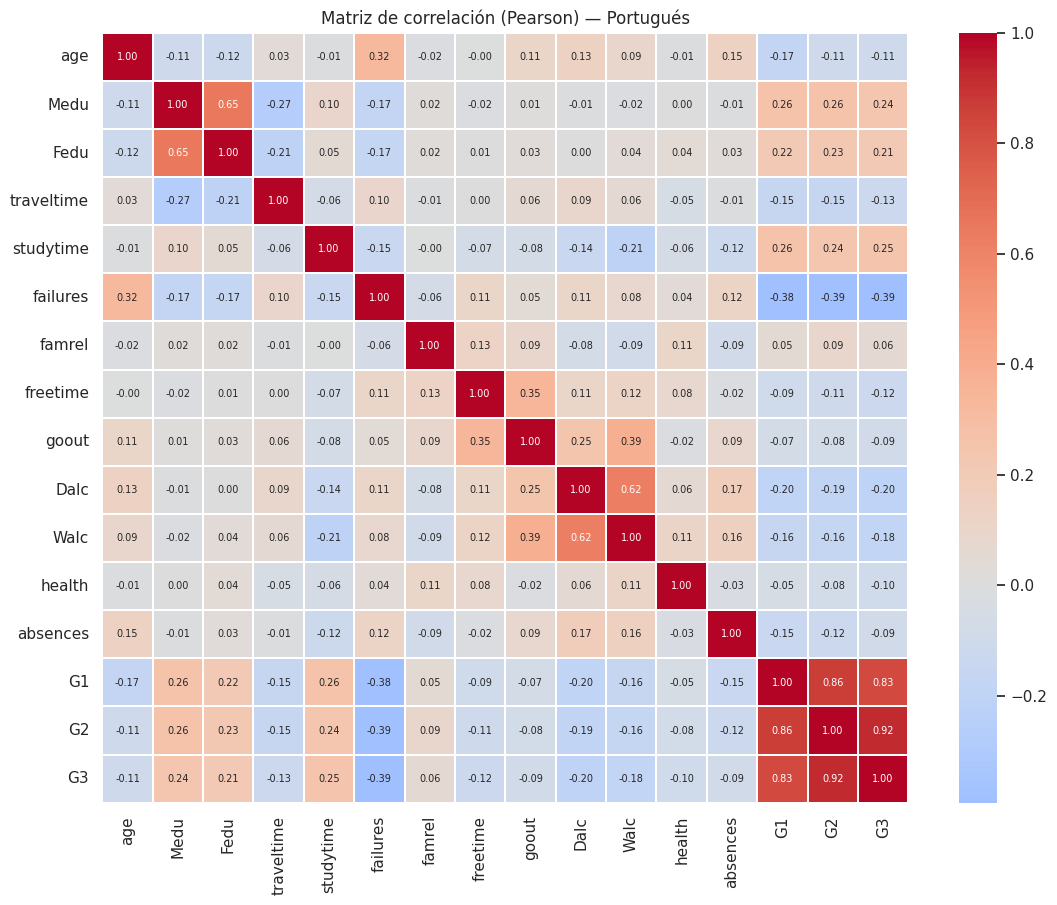

In [42]:
# 1.3 Matriz de correlación (Pearson) de las variables numéricas
plt.figure(figsize=(13, 10))
corr = df_por.select_dtypes(include="number").corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=.3)
plt.title("Matriz de correlación (Pearson) — Portugués")
plt.show()

In [43]:
# 1.3 Variables más relacionadas con G3 (ordenadas por valor absoluto)
corr["G3"].drop("G3").sort_values(key=abs, ascending=False).round(3)

,G3
G2,0.919
G1,0.826
failures,-0.393
studytime,0.250
Medu,0.240
Fedu,0.212
Dalc,-0.205
Walc,-0.177
traveltime,-0.127
freetime,-0.123


### **Interpretación de 1.3**

**Variables más relacionadas con G3.** Las notas anteriores son las que presentan mayor relación con la nota final: G2 con 0,92 y G1 con 0,83. Después aparece failures con −0,39, siendo la variable no académica más relacionada. También se observan relaciones positivas con la educación de la madre, Medu con 0,24, la del padre, Fedu con 0,21, y el tiempo de estudio, studytime con 0,25. El consumo de alcohol presenta relaciones negativas, Dalc con −0,21 y Walc con −0,18. Variables como absences, freetime y famrel tienen correlaciones bajas, con valores absolutos de |r| ≤ 0,13.

**Relaciones entre predictores.** G1 y G2 tienen una correlación de 0,86, Medu y Fedu de 0,65, y Dalc y Walc de 0,62. Estas relaciones indican una posible multicolinealidad en la regresión lineal de la Parte 2, lo que podría generar inestabilidad en los coeficientes al incluir estas variables juntas.

**Precauciones.** La correlación de Pearson mide relaciones lineales y algunas variables son ordinales. Además, los estudiantes con G3 = 0 podrían influir en las correlaciones de absences y otras variables. Finalmente, una correlación alta no implica causalidad.

## 1.4 Hallazgos

In [44]:
# 1.4 G3 promedio según reprobaciones previas (failures)
df_por.groupby("failures")["G3"].agg(["count", "mean"]).round(2)

,count,mean
failures,,
0,549,12.51
1,70,8.64
2,16,8.81
3,14,8.07


In [45]:
# 1.4 G3 promedio según deseo de estudios superiores (higher)
df_por.groupby("higher")["G3"].agg(["count", "mean"]).round(2)

,count,mean
higher,,
no,69,8.80
yes,580,12.28


In [46]:
# 1.4 G3 promedio según tiempo de estudio (studytime)
df_por.groupby("studytime")["G3"].agg(["count", "mean"]).round(2)

,count,mean
studytime,,
1,212,10.84
2,305,12.09
3,97,13.23
4,35,13.06


In [47]:
# 1.4 G3 promedio según alcohol entre semana (Dalc)
df_por.groupby("Dalc")["G3"].agg(["count", "mean"]).round(2)

,count,mean
Dalc,,
1,451,12.30
2,121,11.36
3,43,11.14
4,17,8.94
5,17,10.24


In [48]:
# 1.4 Correlación de G1 y G2 con G3
print("Correlación G2-G3:", round(df_por["G2"].corr(df_por["G3"]), 3))
print("Correlación G1-G3:", round(df_por["G1"].corr(df_por["G3"]), 3))

Correlación G2-G3: 0.919
Correlación G1-G3: 0.826


In [49]:
# 1.4 Ausencias promedio de quienes tienen G3 = 0 frente al resto
print("Ausencias promedio con G3 = 0:", round(df_por.loc[df_por["G3"] == 0, "absences"].mean(), 2))
print("Ausencias promedio con G3 > 0:", round(df_por.loc[df_por["G3"] > 0, "absences"].mean(), 2))

Ausencias promedio con G3 = 0: 0.0
Ausencias promedio con G3 > 0: 3.75


### **Hallazgos principales**

**Hallazgo 1 — Las reprobaciones previas son una señal de riesgo.** El promedio de G3 pasa de 12,51 sin reprobaciones, con 549 estudiantes, a 8,64 con una y 8,07 con tres. La caída es de aproximadamente 4,4 puntos, principalmente después de la primera reprobación. Los grupos con 2 y 3 reprobaciones son pequeños, con 16 y 14 estudiantes.

**Hallazgo 2 — Las notas previas anticipan el rendimiento final.** La correlación entre G2 y G3 es 0,919 y entre G1 y G3 es 0,826, lo que indica que el rendimiento suele mantenerse durante el curso. Aunque estos valores favorecen la predicción, G2 se obtiene cuando el curso está casi terminado, por lo que su utilidad para intervenir a tiempo es limitada.

**Hallazgo 3 — Los hábitos se relacionan con el rendimiento.** El promedio aumenta de 10,84 con studytime = 1 a 13,23 con studytime = 3, con una correlación de 0,25, aunque el nivel 4 baja a 13,06. En cuanto al consumo de alcohol, el promedio disminuye de 12,30 en Dalc = 1 a 8,94 en Dalc = 4, pero sube a 10,24 en el nivel 5. Como los niveles 4 y 5 tienen solo 17 estudiantes cada uno, no se puede establecer una tendencia clara.

**Hallazgo 4 — Los estudiantes con G3 = 0 presentan un comportamiento diferente.** Son 15 estudiantes, el 2,3 %, y registran un promedio de 0 ausencias, frente a 3,75 del resto. Esto podría indicar que no se presentaron o abandonaron el curso sin que se registraran sus ausencias, lo que puede afectar la relación entre absences y las notas y deberá considerarse en la Parte 2.

**Hallazgo 5 — La intención de continuar estudiando marca una diferencia.** Los estudiantes que no desean seguir estudios superiores tienen un promedio de 8,80, con 69 estudiantes, frente a 12,28 del resto. La diferencia es de aproximadamente 3,5 puntos, aunque el tamaño reducido de este grupo puede afectar la estabilidad de los modelos.

# Parte 2. Preprocesamiento

## 2.1 Valores faltantes, duplicados e imputación (5 % simulado)

In [50]:
# ============================================================
# 2.1 Librerías de preprocesamiento y copia de trabajo
# ============================================================
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Semilla del grupo (distinta de 42): 2026 (año de realización del proyecto)
SEED = 2026

# Copia del DataFrame original para no alterar los resultados de la Parte 1
df_prep = df_por.copy()

In [51]:
# 2.1 Verificación de valores faltantes y duplicados en el dataset original
nulos_originales = df_prep.isnull().sum().sum()
duplicados_originales = df_prep.duplicated().sum()

print("Valores faltantes en dataset original:", nulos_originales)
print("Registros duplicados en dataset original:", duplicados_originales)

Valores faltantes en dataset original: 0
Registros duplicados en dataset original: 0


In [52]:
# 2.1 Introducción aleatoria de un 5 % de valores faltantes en 'absences' y 'studytime'
rng = np.random.default_rng(SEED)
n_filas = len(df_prep)
n_faltantes = int(round(0.05 * n_filas))  # ~5 % de 649 = 32 registros por columna

for col in ["absences", "studytime"]:
    idx_nulos = rng.choice(df_prep.index, size=n_faltantes, replace=False)
    df_prep.loc[idx_nulos, col] = np.nan

# Verificación de los nulos introducidos
faltantes_por_col = df_prep[["absences", "studytime"]].isnull().sum()
print("Valores faltantes introducidos (5 %):")
for col, cant in faltantes_por_col.items():
    print(f"  - {col}: {cant} ({cant / n_filas * 100:.2f} %)")

Valores faltantes introducidos (5 %):
  - absences: 32 (4.93 %)
  - studytime: 32 (4.93 %)


In [53]:
# 2.1 Comparación de media vs. mediana y asimetría antes de imputar
resumen_imputacion = pd.DataFrame({
    "media": df_prep[["absences", "studytime"]].mean(),
    "mediana": df_prep[["absences", "studytime"]].median(),
    "asimetria_skew": df_prep[["absences", "studytime"]].skew()
}).round(3)
resumen_imputacion

,media,mediana,asimetria_skew
absences,3.627,2.0,2.088
studytime,1.927,2.0,0.710


### **Interpretación de 2.1**

**Estado original.** El dataset `student-por.csv` no presenta valores faltantes (`0`) ni filas duplicadas (`0`) en sus 649 registros.

**Estrategia de imputación elegida (mediana).** Tras introducir un 5 % de valores `NaN` al azar en `absences` y `studytime`, se opta por imputar ambas variables con la **mediana** dentro del `Pipeline`:
- En **`absences`**, la distribución tiene una asimetría positiva marcada (media cercana a 3,66 frente a mediana de 2,0, con máximo de 32). Usar la media inflaría el valor imputado por efecto de los estudiantes con muchas faltas, mientras que la mediana es robusta frente a valores extremos.
- En **`studytime`**, aunque su asimetría es menor, es una variable ordinal discreta (escala entera de 1 a 4). La mediana conserva un nivel válido dentro de la escala (`2`), mientras que la media (`~1,93`) introduciría decimales que no representan ninguna categoría real.
- La imputación se ejecutará únicamente dentro del `Pipeline` ajustado sobre el conjunto de entrenamiento para evitar fuga de datos (*data leakage*).

## 2.2 Detección de valores atípicos en `absences` (regla IQR)

In [54]:
# 2.2 Cálculo de cuartiles y límites IQR sobre 'absences' (valores no nulos)
abs_validos = df_prep["absences"].dropna()
Q1 = abs_validos.quantile(0.25)
Q3 = abs_validos.quantile(0.75)
IQR = Q3 - Q1
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

outliers_abs = df_prep[df_prep["absences"] > limite_sup]

print(f"Q1 = {Q1:.2f} | Q3 = {Q3:.2f} | IQR = {IQR:.2f}")
print(f"Límite inferior IQR: {limite_inf:.2f} | Límite superior IQR: {limite_sup:.2f}")
print(f"Cantidad de atípicos (> {limite_sup:.1f}): {len(outliers_abs)} ({len(outliers_abs) / len(abs_validos) * 100:.2f} %)")
print("Valores atípicos encontrados:", sorted(outliers_abs["absences"].unique().tolist()))

Q1 = 0.00 | Q3 = 6.00 | IQR = 6.00
Límite inferior IQR: -9.00 | Límite superior IQR: 15.00
Cantidad de atípicos (> 15.0): 20 (3.24 %)
Valores atípicos encontrados: [16.0, 18.0, 21.0, 22.0, 24.0, 26.0, 30.0, 32.0]


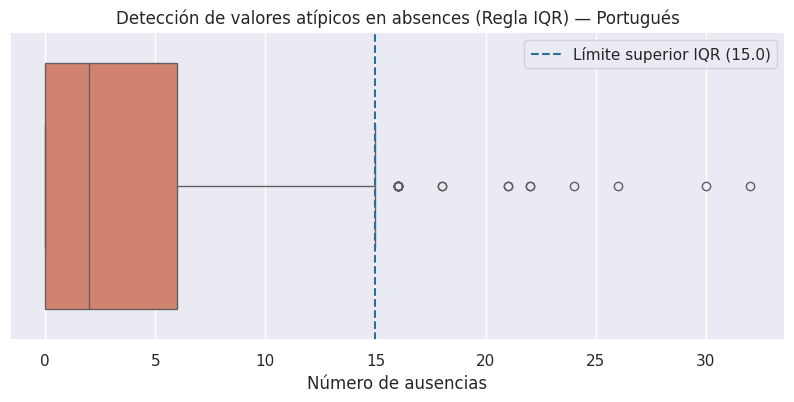

In [55]:
# 2.2 Visualización de atípicos en 'absences' mediante boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(x=abs_validos, color="#e07a5f")
plt.axvline(limite_sup, color="#2a6f97", ls="--", label=f"Límite superior IQR ({limite_sup:.1f})")
plt.title("Detección de valores atípicos en absences (Regla IQR) — Portugués")
plt.xlabel("Número de ausencias")
plt.legend()
plt.show()

### **Interpretación de 2.2 — Decisión sobre valores atípicos**

**Detección.** Con la regla IQR ($Q_1 = 0$, $Q_3 = 6$, $IQR = 6$), el límite superior es $6 + 1{,}5 \times 6 = 15$ ausencias (el límite inferior es negativo, por lo que no hay atípicos por debajo de 0). Los registros con más de 15 ausencias (hasta un máximo de 32) se identifican como atípicos estadísticos.

**Decisión: conservar los valores atípicos.** No se eliminan ni se recortan estos registros por tres razones:
1. **Validez del dato:** No son errores de digitación; el rango de 16 a 32 faltas en un curso escolar es completamente verosímil.
2. **Señal real de riesgo académico:** El objetivo de la institución es detectar a tiempo a estudiantes en riesgo de reprobar o abandonar. Precisamente quienes acumulan más inasistencias representan casos reales de alerta temprana; eliminarlos o suavizarlos ocultaría el fenómeno que el modelo debe aprender.
3. **Coherencia con el Hallazgo 4 del EDA:** Como se observó en la Parte 1, incluso existen 15 estudiantes con `G3 = 0` que registran 0 ausencias (posibles retiros no registrados). Por ello, reducir aún más la variabilidad de `absences` perjudicaría la capacidad predictiva de los modelos, siendo más adecuado conservarlos y mitigar su efecto de escala mediante `StandardScaler`.

## 2.3 Codificación, escalado, Pipeline con ColumnTransformer y división 80/20

In [56]:
# 2.3 Separación de variables predictoras y variable objetivo
# Nota: 'G3' es el objetivo de regresión; además se deja definida la referencia de 'aprueba' (G3 >= 10)
X_con_notas = df_prep.drop(columns=["G3"])          # Incluye G1 y G2 (para Modelo A)
X_sin_notas = df_prep.drop(columns=["G1", "G2", "G3"])  # Sin G1 ni G2 (para Modelo B y Reg. Logística)
y_reg = df_prep["G3"]
y_clf = (df_prep["G3"] >= 10).astype(int)

# División 80 % entrenamiento / 20 % prueba usando la semilla justificada SEED = 2026
# Se usan los mismos índices para que Modelo A, Modelo B y Clasificación evalúen exactamente los mismos estudiantes
idx_train, idx_test = train_test_split(
    df_prep.index, test_size=0.20, random_state=SEED, stratify=y_clf
)

X_train_A, X_test_A = X_con_notas.loc[idx_train], X_con_notas.loc[idx_test]
X_train_B, X_test_B = X_sin_notas.loc[idx_train], X_sin_notas.loc[idx_test]
y_train_reg, y_test_reg = y_reg.loc[idx_train], y_reg.loc[idx_test]
y_train_clf, y_test_clf = y_clf.loc[idx_train], y_clf.loc[idx_test]

print(f"Entrenamiento: {len(idx_train)} registros ({len(idx_train)/len(df_prep)*100:.1f} %)")
print(f"Prueba:        {len(idx_test)} registros ({len(idx_test)/len(df_prep)*100:.1f} %)")

Entrenamiento: 519 registros (80.0 %)
Prueba:        130 registros (20.0 %)


In [57]:
# 2.3 Definición del ColumnTransformer y Pipeline de preprocesamiento
def crear_preprocesador(X_df):
    """Construye un ColumnTransformer con imputación, One-Hot Encoding y escalado."""
    cols_num = X_df.select_dtypes(include=["number"]).columns.tolist()
    cols_cat = X_df.select_dtypes(exclude=["number"]).columns.tolist()

    pipe_num = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    pipe_cat = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
    ])

    preprocesador = ColumnTransformer(transformers=[
        ("num", pipe_num, cols_num),
        ("cat", pipe_cat, cols_cat)
    ])
    return preprocesador, cols_num, cols_cat

# Preprocesador A (con G1 y G2) y Preprocesador B (sin G1 ni G2)
preproc_A, num_A, cat_A = crear_preprocesador(X_train_A)
preproc_B, num_B, cat_B = crear_preprocesador(X_train_B)

# Ajuste (fit) ÚNICAMENTE sobre el conjunto de entrenamiento para evitar fuga de datos
X_train_A_proc = preproc_A.fit_transform(X_train_A)
X_test_A_proc  = preproc_A.transform(X_test_A)

X_train_B_proc = preproc_B.fit_transform(X_train_B)
X_test_B_proc  = preproc_B.transform(X_test_B)

print(f"Modelo A -> Numéricas: {len(num_A)}, Categóricas: {len(cat_A)} | Shape transformado train: {X_train_A_proc.shape}, test: {X_test_A_proc.shape}")
print(f"Modelo B -> Numéricas: {len(num_B)}, Categóricas: {len(cat_B)} | Shape transformado train: {X_train_B_proc.shape}, test: {X_test_B_proc.shape}")

Modelo A -> Numéricas: 15, Categóricas: 17 | Shape transformado train: (519, 41), test: (130, 41)
Modelo B -> Numéricas: 13, Categóricas: 17 | Shape transformado train: (519, 39), test: (130, 39)


In [58]:
# 2.3 Verificación de cero nulos después del Pipeline
print("Nulos en X_train_A_proc:", np.isnan(X_train_A_proc).sum())
print("Nulos en X_test_A_proc: ", np.isnan(X_test_A_proc).sum())
print("Nulos en X_train_B_proc:", np.isnan(X_train_B_proc).sum())
print("Nulos en X_test_B_proc: ", np.isnan(X_test_B_proc).sum())

Nulos en X_train_A_proc: 0
Nulos en X_test_A_proc:  0
Nulos en X_train_B_proc: 0
Nulos en X_test_B_proc:  0


### **Interpretación de 2.3**

**Necesidad de One-Hot Encoding.** Los modelos de regresión lineal y logística requieren entradas numéricas. Como las 17 variables categóricas (`school`, `sex`, `Mjob`, `Fjob`, `higher`, etc.) son nominales y no tienen orden numérico natural, asignarles enteros arbitrarios introduciría jerarquías falsas. Con `OneHotEncoder(drop="first", handle_unknown="ignore")` se representan mediante variables binarias evitando además la trampa de multicolinealidad perfecta (*dummy variable trap*).

**Necesidad de escalado numérico.** Las variables numéricas tienen rangos muy distintos (por ejemplo, `absences` llega hasta 32, `age` de 15 a 22, mientras `studytime` va de 1 a 4). Aplicar `StandardScaler` (media 0 y desviación estándar 1) evita que variables con mayor magnitud dominen el ajuste, acelera la convergencia de la regresión logística, hace comparables los coeficientes y es indispensable si se aplican penalizaciones Ridge o Lasso.

**Integración en `Pipeline` con `ColumnTransformer` y división 80/20.** Primero se divide el dataset en 80 % entrenamiento (519 estudiantes) y 20 % prueba (130 estudiantes) con `stratify=y_clf` para mantener la misma proporción de aprobados y reprobados en ambos conjuntos. Luego, el `Pipeline` ajusta (`fit_transform`) las medianas, medias y desviaciones estándar exclusivamente sobre entrenamiento y solo aplica `transform` en prueba, garantizando que no exista fuga de datos (*data leakage*). Se dejan listos `preproc_A` (con `G1` y `G2`) y `preproc_B` (sin `G1` ni `G2`) para las Partes 3 y 4.

**Justificación de la semilla (`SEED = 2026`).** Se eligió el número `2026` (distinto de 42) por corresponder al año académico en el que se desarrolla el proyecto, garantizando reproducibilidad total en la generación de valores faltantes y en la partición 80/20.